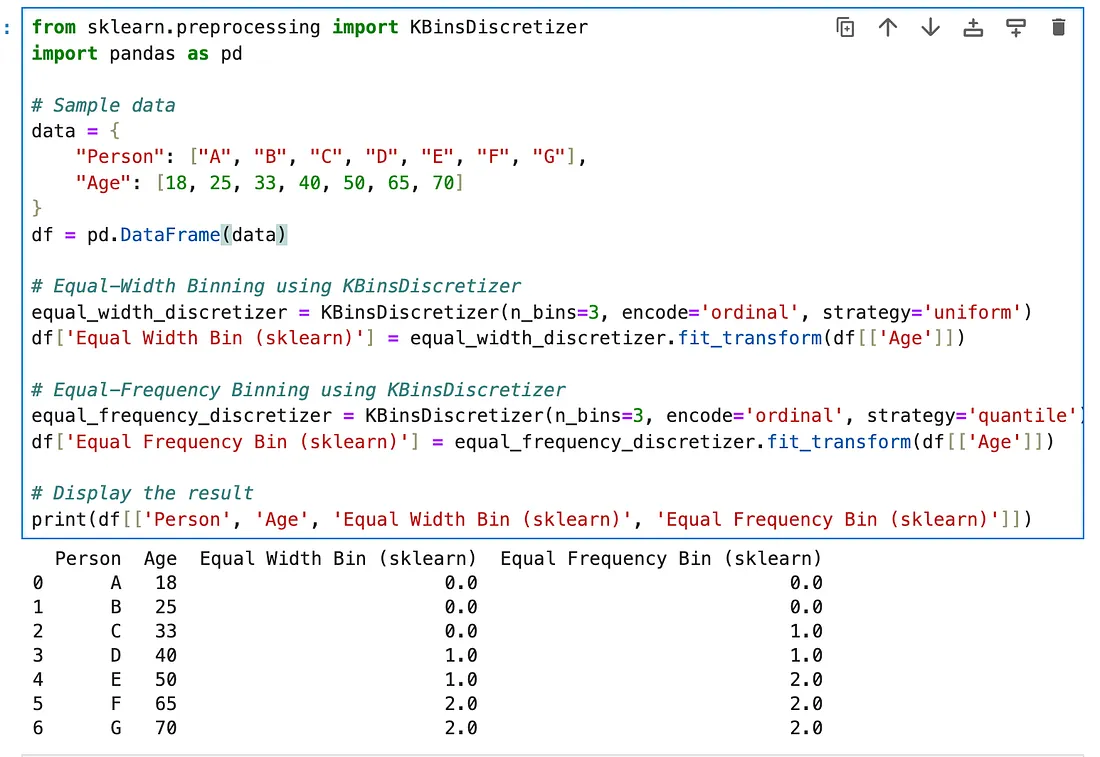

In [ ]:
from sklearn.preprocessing import KBinsDiscretizer
import pandas as pd

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn import tree


In [ ]:
df=pd.read_csv('train.csv',usecols=['Age','Fare','Survived'])
df


FileNotFoundError: [Errno 2] No such file or directory: 'train.csv'

In [ ]:
df.dropna(inplace=True)
df.shape

**Binning without**

In [ ]:
x=df.iloc[:,1:]
y=df.iloc[:,0]

In [ ]:
X_train,X_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [ ]:
X_train.head(2)

In [ ]:
clf=DecisionTreeClassifier()
clf.fit(X_train,y_train)
y_pred=clf.predict(X_test)
accuracy_score(y_test,y_pred)

In [ ]:
np.mean(cross_val_score(DecisionTreeClassifier(),X_train,y_train,cv=10,scoring='accuracy'))

**Appaying Discretizer**

In [ ]:
equal_width_discretizer = KBinsDiscretizer(
    n_bins=3,
    encode='ordinal',
    strategy='uniform'
)

width_bin=df['Equal Width Bin (sklearn)'] = (
    equal_width_discretizer.fit_transform(df[['Age']])
)

print(width_bin)

equal-frequency-binaning

In [ ]:
equal_frequency_discretizer = KBinsDiscretizer(
    n_bins=3,
    encode='ordinal',
    strategy='quantile'
)

equal_fre=df['Equal Frequency Bin (sklearn)'] = (
    equal_frequency_discretizer.fit_transform(df[['Age']])
)
print(equal_fre)

In [ ]:
import pandas as pd

# Load Titanic dataset
df = pd.read_csv("train.csv")

# Check columns and missing values
print(df[["Age", "Fare", "Survived"]].isnull().sum())

# Handle missing values in Age and Fare
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Fare"] = df["Fare"].fillna(df["Fare"].median())

# 1. Age binning: equal-width bins
df["Age_Group"] = pd.cut(
    df["Age"],
    bins=[0, 12, 18, 35, 60, float("inf")],
    labels=["Child", "Teenager", "Young Adult", "Adult", "Senior"],
    include_lowest=True
)

# 2. Fare binning: equal-frequency bins
df["Fare_Group"] = pd.qcut(
    df["Fare"],
    q=4,
    labels=["Low", "Medium", "High", "Very High"],
    duplicates="drop"
)

# 3. Survived: keep as binary target
df["Survived"] = df["Survived"].astype("int64")

# View results
print(df[["Age", "Age_Group", "Fare", "Fare_Group", "Survived"]].head(10))

**HAndaling mixed variable**

In [ ]:
df

NameError: name 'df' is not defined